In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

a = pd.read_csv("../results/metrics/ocr_llm_v4_test.csv", index_col="field")
d = pd.read_csv("../results/metrics/donut_test.csv", index_col="field")

ORDER = ["total_price", "subtotal_price", "tax_price", "cashprice", "changeprice", "ALL"]
LABELS = ["Total", "Subtotal", "Tax", "Cash", "Change", "All fields"]
METHODS = [
    ("OCR + LLM (EasyOCR + Qwen3 4B, no training)", a, "#2a78d6"),
    ("Donut (fine-tuned on CORD)", d, "#eb6834"),
]
TEXT_PRIMARY, TEXT_SECONDARY, GRID, AXIS = "#0b0b0b", "#52514e", "#e5e4e0", "#b8b7b0"

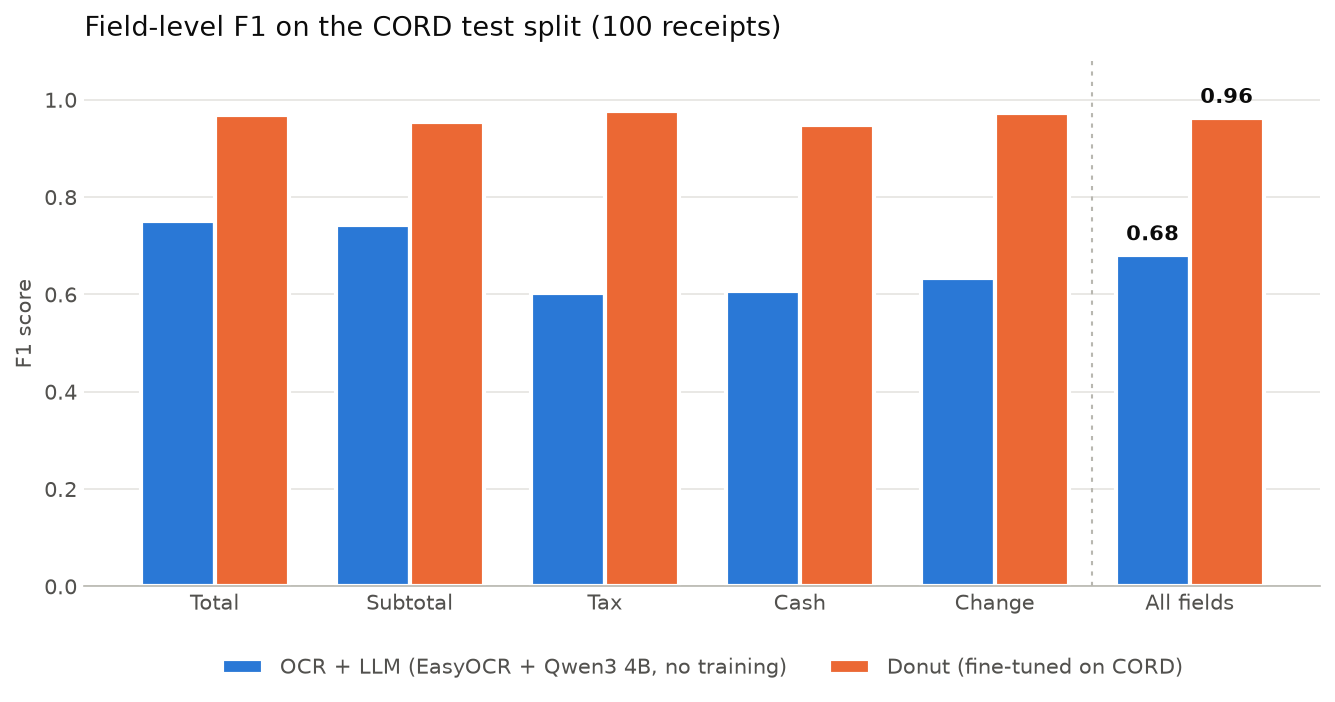

In [2]:
x = np.arange(len(ORDER))
width = 0.38
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=150)

for i, (name, df, color) in enumerate(METHODS):
    offset = (i - 0.5) * width
    values = df.loc[ORDER, "f1"].to_numpy()
    ax.bar(x + offset, values, width, color=color, label=name, edgecolor="white", linewidth=2)
    ax.text(x[-1] + offset, values[-1] + 0.02, f"{values[-1]:.2f}",
            ha="center", va="bottom", fontsize=10, color=TEXT_PRIMARY, fontweight="bold")

ax.axvline(x[-1] - 0.5, color=AXIS, linewidth=1, linestyle=(0, (2, 3)))
ax.set_xticks(x, LABELS)
ax.set_ylim(0, 1.08)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel("F1 score", color=TEXT_SECONDARY)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.tick_params(colors=TEXT_SECONDARY, length=0)
ax.set_title("Field-level F1 on the CORD test split (100 receipts)", loc="left",
             color=TEXT_PRIMARY, fontsize=13, pad=12)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, labelcolor=TEXT_SECONDARY)

fig.tight_layout()
Path("../results/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../results/figures/f1_comparison.png", facecolor="white", bbox_inches="tight")
plt.show()